# Segnali, versione 2: rilettura del Passaggio 4 dopo i costi

**Perché.** Il backtest ([backtest_A.ipynb](backtest_A.ipynb)) ha mostrato che con le regole del Passaggio 4 il guadagno lordo (6.77 bps per trade) non copre i costi: costo di pareggio 1.69 bps per operazione. Qui proviamo tre cambiamenti, **solo sul train**, senza modificare i file esistenti (`signals.py`, `segnali_coppie.ipynb`, `backtest.py`). Il codice è in [signals_v2.py](signals_v2.py).

**Le tre leve e la griglia (18 combinazioni, scritta prima dei risultati)**

| Leva | Valori | Note |
|---|---|---|
| Scostamento minimo in bps | 0, 8, 20 | Si entra solo se \|S - EMA\| >= X bps, oltre a \|z\| >= 2. 0 = regole attuali; 8 = costo di un trade a 2 bps per operazione; 20 = costo a 5 bps |
| Tempo massimo | 90, 180 minuti, solo fine giornata (390) | 90 = attuale |
| Barre del segnale | 1 e 5 minuti | Con 5 minuti lo z-score è calcolato sulle barre da 5 (emivita 60 minuti = 12 barre) e si decide alla chiusura della barra; l'esecuzione è all'apertura del minuto dopo |

Fissi: emivita 60 minuti, ingresso z 2.0, uscita 0, stop 3.5, niente ingressi nei primi 15 e negli ultimi 30 minuti, EMA continua, non si apre con una gamba ferma. Il gap della notte resta e si dichiara.

**Regola di scelta (scritta prima)**
1. Controllo: la combinazione (0 bps, 90 minuti, 1 minuto) deve riprodurre i 624 trade del Passaggio 4.
2. Il train si divide in due metà per giorni: i primi 32 giorni servono a scegliere, gli ultimi 32 a controllare.
3. Obiettivo sulla prima metà: guadagno netto medio a **2 bps per operazione**, con almeno **150 trade** in quella metà.
4. La combinazione scelta è valida solo se il netto a 2 bps è positivo anche nella seconda metà. Se no, la dichiariamo non valida e non ne scegliamo un'altra a posteriori.
5. Si riportano sempre anche i risultati a 5 bps (scenario realistico del backtest), per coppia, per finestra d'ingresso e per motivo di uscita.
6. Il test (dal 17 settembre) non si legge. Le combinazioni provate qui sono 18, in più delle 32 del Passaggio 4: va scritto nel report.

## 1. Parametri e calcolo della griglia

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signals import list_pairs
from signals_v2 import run_grid, finalize
from backtest import trading_days, add_costs, by_cost, by_group, entry_window, breakeven_cost, daily_pnl, load_trades, MAIN_COST

pd.options.display.float_format = "{:,.2f}".format
BARS, DEVS, HOLDS = [1, 5], [0, 8, 20], [90, 180, 390]
COST_SELECT, MIN_TRADES_HALF1 = 2, 150
BASELINE = dict(bars=1, min_dev_bps=0, max_hold=90)

pairs = list_pairs().pair.tolist()
grid = finalize(run_grid(pairs, BARS, DEVS, HOLDS))
days = trading_days()
cut = days[31]                       # ultimo giorno della prima metà (32 giorni)
grid["half"] = np.where(grid.t_signal.dt.normalize() <= cut, 1, 2)
print(len(grid), "trade in totale su", grid.groupby(["bars", "min_dev_bps", "max_hold"]).ngroups, "combinazioni;",
      "prima metà fino al", cut.date(), "(", (days <= cut).sum(), "giorni ), seconda metà", (days > cut).sum(), "giorni")

8312 trade in totale su 18 combinazioni; prima metà fino al 2026-07-31 ( 32 giorni ), seconda metà 32 giorni


## 2. Controllo di coerenza con il Passaggio 4

In [2]:
old = load_trades()
base = grid[(grid.bars == 1) & (grid.min_dev_bps == 0) & (grid.max_hold == 90)]
assert len(base) == len(old) == 624, (len(base), len(old))
m = base.merge(old, on=["pair", "t_entry"], suffixes=("", "_old"))
assert len(m) == 624 and np.allclose(m.gross_bps, m.gross_bps_old) and (m.t_exit == m.t_exit_old).all()
print("controllo ok: stessi 624 trade, stessi orari di uscita e stessi guadagni lordi del Passaggio 4")

controllo ok: stessi 624 trade, stessi orari di uscita e stessi guadagni lordi del Passaggio 4


## 3. Tutte le combinazioni

In [3]:
def stats(t, c):
    net = t.gross_bps - 4 * c
    return len(t), net.mean() if len(t) else np.nan

rows = []
for (b, dv, h), t in grid.groupby(["bars", "min_dev_bps", "max_hold"]):
    t1, t2 = t[t.half == 1], t[t.half == 2]
    rows.append(dict(bars=b, min_dev_bps=dv, max_hold=h, trade=len(t), gross=t.gross_bps.mean(),
                     net2=stats(t, 2)[1], net5=stats(t, 5)[1],
                     n_h1=len(t1), gross_h1=t1.gross_bps.mean(), net2_h1=stats(t1, 2)[1],
                     n_h2=len(t2), gross_h2=t2.gross_bps.mean(), net2_h2=stats(t2, 2)[1], net5_h2=stats(t2, 5)[1]))
res = pd.DataFrame(rows)
res

,bars,min_dev_bps,max_hold,trade,gross,net2,net5,n_h1,gross_h1,net2_h1,n_h2,gross_h2,net2_h2,net5_h2
0,1,0,90,624,6.77,-1.23,-13.23,319,11.10,3.10,305,2.24,-5.76,-17.76
1,1,0,180,620,5.85,-2.15,-14.15,318,10.42,2.42,302,1.04,-6.96,-18.96
2,1,0,390,617,5.89,-2.11,-14.11,318,11.31,3.31,299,0.11,-7.89,-19.89
3,1,8,90,624,6.77,-1.23,-13.23,319,11.10,3.10,305,2.24,-5.76,-17.76
4,1,8,180,620,5.85,-2.15,-14.15,318,10.42,2.42,302,1.04,-6.96,-18.96
5,1,8,390,617,5.89,-2.11,-14.11,318,11.31,3.31,299,0.11,-7.89,-19.89
6,1,20,90,610,6.92,-1.08,-13.08,316,11.18,3.18,294,2.34,-5.66,-17.66
7,1,20,180,607,5.97,-2.03,-14.03,315,10.50,2.50,292,1.09,-6.91,-18.91
8,1,20,390,604,6.01,-1.99,-13.99,315,11.39,3.39,289,0.14,-7.86,-19.86
9,5,0,90,309,6.43,-1.57,-13.57,152,9.06,1.06,157,3.89,-4.11,-16.11


## 4. Scelta con la regola scritta sopra

In [4]:
eligible = res[res.n_h1 >= MIN_TRADES_HALF1]
best = eligible.sort_values("net2_h1", ascending=False).iloc[0]
cfg = dict(bars=int(best.bars), min_dev_bps=int(best.min_dev_bps), max_hold=int(best.max_hold))
print("Combinazioni con almeno", MIN_TRADES_HALF1, "trade nella prima metà:", len(eligible), "su", len(res))
print("Scelta:", cfg)
print(f"Prima metà: {int(best.n_h1)} trade, netto a 2 bps {best.net2_h1:.2f} bps (lordo {best.gross_h1:.2f})")
print(f"Seconda metà: {int(best.n_h2)} trade, netto a 2 bps {best.net2_h2:.2f} bps, a 5 bps {best.net5_h2:.2f} bps (lordo {best.gross_h2:.2f})")
valid = best.net2_h1 > 0 and best.net2_h2 > 0
print("VALIDA" if valid else "NON VALIDA: il netto a 2 bps non è positivo in entrambe le metà", "- non si sceglie un'altra combinazione a posteriori")

Combinazioni con almeno 150 trade nella prima metà: 18 su 18
Scelta: {'bars': 1, 'min_dev_bps': 20, 'max_hold': 390}
Prima metà: 315 trade, netto a 2 bps 3.39 bps (lordo 11.39)
Seconda metà: 289 trade, netto a 2 bps -7.86 bps, a 5 bps -19.86 bps (lordo 0.14)
NON VALIDA: il netto a 2 bps non è positivo in entrambe le metà - non si sceglie un'altra combinazione a posteriori


## 5. Dettaglio della combinazione scelta (intero train)

In [5]:
chosen = grid[(grid.bars == cfg["bars"]) & (grid.min_dev_bps == cfg["min_dev_bps"]) & (grid.max_hold == cfg["max_hold"])].reset_index(drop=True)
chosen["signal_id"] = np.arange(len(chosen))
print(len(chosen), "trade, lordo", round(chosen.gross_bps.mean(), 2), "bps, costo di pareggio", round(breakeven_cost(chosen), 2), "bps per operazione")
by_cost(chosen, days)[["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "total_return", "sharpe", "max_drawdown"]]

604 trade, lordo 6.01 bps, costo di pareggio 1.5 bps per operazione


,trade,gross_bps,net_bps,se_bps,win_rate,profit_factor,total_return,sharpe,max_drawdown
cost_bps_per_operation,,,,,,,,,
0,604.00,6.01,6.01,2.37,0.65,1.35,0.02,5.03,-0.00
2,604.00,6.01,-1.99,2.37,0.59,0.90,-0.01,-1.66,-0.01
5,604.00,6.01,-13.99,2.37,0.42,0.47,-0.04,-11.25,-0.04
10,604.00,6.01,-33.99,2.37,0.19,0.16,-0.10,-24.24,-0.10


In [6]:
by_group(chosen, "pair")

,trade,gross_bps,net_bps,se_bps,win_rate
pair,,,,,
BAC-PNC,61,-3.49,-23.49,6.49,0.41
BNY-GS,51,10.50,-9.50,9.50,0.57
CSX-UNP,61,11.91,-8.09,4.06,0.44
HD-LOW,64,2.92,-17.08,5.10,0.41
ITW-OTIS,53,3.66,-16.34,6.80,0.45
KO-PEP,66,-0.23,-20.23,6.84,0.33
MA-V,71,9.87,-10.13,2.70,0.30
MCD-YUM,63,5.77,-14.23,9.05,0.51
PYPL-XYZ,58,21.47,1.47,14.76,0.59


In [7]:
pd.concat({"finestra": by_group(chosen, entry_window(chosen)), "uscita": by_group(chosen, "exit_reason")})

trade  gross_bps  net_bps  se_bps  win_rate
finestra apertura (15-30 min)    269      11.43    -8.57    4.11      0.48
         dopo i 30 min           335       1.65   -18.35    2.71      0.38
uscita   fine_giornata            69     -58.10   -78.10   11.33      0.04
         rientro                 521      15.69    -4.31    2.00      0.48
         stop                     14     -38.09   -58.09    7.58      0.00

In [8]:
# confronto con le regole del Passaggio 4 allo stesso costo
for name, t in [("Passaggio 4", base), ("scelta v2", chosen)]:
    s = add_costs(t, MAIN_COST)
    print(f"{name}: {len(t)} trade, lordo {t.gross_bps.mean():.2f}, netto a {MAIN_COST} bps {s.net_bps.mean():.2f}, a 2 bps {add_costs(t, 2).net_bps.mean():.2f}")

Passaggio 4: 624 trade, lordo 6.77, netto a 5 bps -13.23, a 2 bps -1.23
scelta v2: 604 trade, lordo 6.01, netto a 5 bps -13.99, a 2 bps -1.99


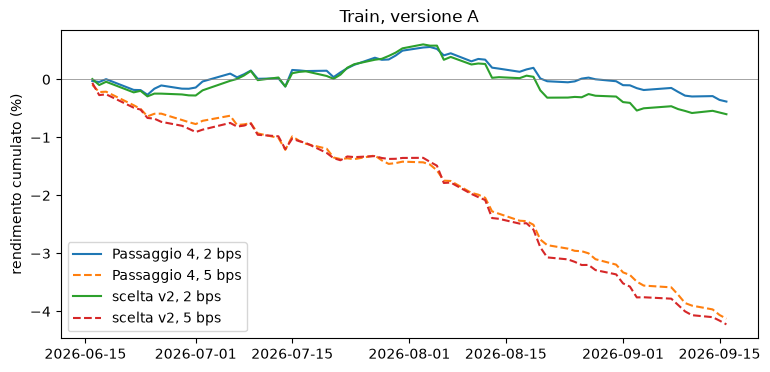

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, t in [("Passaggio 4", base), ("scelta v2", chosen)]:
    for c, ls in [(2, "-"), (5, "--")]:
        d = daily_pnl(add_costs(t, c), days)
        ax.plot(d.index, d.equity * 100, ls, label=f"{name}, {c} bps")
ax.axhline(0, color="grey", lw=0.5); ax.set_ylabel("rendimento cumulato (%)"); ax.legend(); ax.set_title("Train, versione A")
plt.show()

In [10]:
from pathlib import Path
OUT = Path("../data/processed/signals_v2_train.csv")
chosen.drop(columns=["half"]).to_csv(OUT, index=False)
print("salvato", OUT, len(chosen), "trade")

salvato ../data/processed/signals_v2_train.csv 604 trade


## 6. Cosa ci dicono i risultati

Controllo di coerenza superato (stessi 624 trade del Passaggio 4). Tutte le 18 combinazioni hanno almeno 150 trade nella prima metà, quindi la regola di scelta le considera tutte.

- **Nessuna combinazione regge.** La regola sceglie (1 minuto, 20 bps, solo fine giornata): +3.4 bps netti a 2 bps nella prima metà, ma **-7.9 bps nella seconda**. È **non valida** per la regola scritta prima, e non ne scegliamo un'altra. Su tutto il train è netta negativa a 2 bps (-2.0) e a 5 bps (-14.0), peggio del Passaggio 4 (-1.2 e -13.2).
- **Il problema vero è la stabilità, non i parametri.** Con le regole del Passaggio 4 il guadagno lordo è 11.1 bps nei primi 32 giorni e **2.2 bps negli ultimi 32**. Con barre da 5 minuti 9.1 e 3.9. Il guadagno del Passaggio 4 viene quasi tutto da luglio. Nessuna delle 18 combinazioni ha un lordo nella seconda metà sopra 4 bps, quindi nessuna copre nemmeno i costi più bassi (8 bps a 2 bps per operazione).
- **La soglia minima in bps non serve ai valori provati.** Con 8 bps i trade sono identici a quelli senza soglia; con 20 bps ne cadono solo 14 su 624. A z = 2 lo scostamento dalla EMA è quasi sempre già sopra 20 bps, quindi i trade che scartiamo non sono quelli sbagliati. I valori di 8 e 20 erano nati dai costi, e il risultato dice che non sono la soglia che separa trade buoni e cattivi. Provarne di più alti sarebbe una nuova scelta da dichiarare.
- **Tempo massimo.** Allungarlo peggiora: con 180 minuti il lordo scende da 6.8 a 5.9 bps e con "solo fine giornata" i trade chiusi a fine giornata (69) perdono 58 bps in media. Il rientro entro il limite resta l'unico esito positivo (521 trade, +15.7 bps lordi, ma sotto i costi a 5 bps).
- **Barre da 5 minuti.** Dimezzano i trade (309) e tolgono il rumore, ma il lordo non migliora (6.4 bps con 90 minuti) e resta dentro l'incertezza (errori standard di 3-4 bps).
- **Gap della notte.** Con la combinazione scelta: 269 trade con ingresso nei minuti 15-30 a 11.4 bps lordi, 335 dopo i 30 minuti a 1.7 bps. Resta la stessa struttura del Passaggio 4.

**Conclusione.** Le tre leve provate non portano il segnale in guadagno netto, e il confronto tra le due metà dice che la differenza tra "funziona" e "non funziona" è dovuta più al periodo che alle regole: con 64 giorni di train un risultato così non è distinguibile dal caso. Questo vale per qualsiasi variante del segnale, e va scritto nel report.

**Limiti.** 18 combinazioni in più delle 32 del Passaggio 4; il train è lo stesso su cui sono stati scelti i parametri attuali; la divisione in due metà dà solo 32 giorni ciascuna; il file `signals_v2_train.csv` contiene la combinazione scelta dalla regola anche se non valida, e non va usato come input dell'agente senza dichiararlo.